# Redes Neuronales III — Optimización y regularización

**Estudiante:** Ruby Dayana Cárdenas Gómez  
**Universidad:** Universidad de Cundinamarca  
**CADI:** Deep Learning — Conceptos  
**Docente:** Nidia Stella García Roa

Esta práctica compara tres optimizadores y analiza el efecto conjunto de Dropout, regularización L2 y Early Stopping en una red neuronal binaria. El conjunto de datos se divide en **train/dev/test** antes de ajustar el escalador, para evitar fuga de información.


## 1 Objetivos

- Reconocer los hiperparámetros que controlan el entrenamiento.
- Comparar SGD con momentum, RMSprop y Adam bajo la misma arquitectura.
- Aplicar Dropout, L2 y Early Stopping para controlar el sobreajuste.
- Evaluar una sola vez sobre test después de elegir la configuración con dev.


In [1]:
import json
import os
import random
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential, regularizers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Dropout, Input

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")

print("TensorFlow:", tf.__version__)
print("Semilla:", SEED)


TensorFlow: 2.20.0
Semilla: 42


## 2 Datos y distribución

Se utiliza Breast Cancer Wisconsin, incluido en scikit-learn. Cada registro contiene 30 mediciones calculadas a partir de una imagen digitalizada de una masa mamaria. La etiqueta 0 representa un tumor maligno y la etiqueta 1 uno benigno.


In [2]:
dataset = load_breast_cancer()
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="diagnostico")

distribucion = y.value_counts().sort_index().rename(index={0: "Maligno", 1: "Benigno"})
display(pd.DataFrame({"Cantidad": distribucion, "Porcentaje": (distribucion / len(y) * 100).round(2)}))
print("Dimensión de X:", X.shape)


,Cantidad,Porcentaje
diagnostico,,
Maligno,212,37.26
Benigno,357,62.74


Dimensión de X: (569, 30)


## 3 Separación train dev test

La partición estratificada conserva la proporción de clases. Train ajusta los pesos, dev permite comparar hiperparámetros y test mide la generalización final. El conjunto test no interviene en la selección del modelo.


In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_dev, X_test, y_dev, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

particiones = pd.DataFrame({
    "Partición": ["Train", "Dev", "Test"],
    "Registros": [len(X_train), len(X_dev), len(X_test)],
    "Porcentaje": [len(X_train), len(X_dev), len(X_test)],
})
particiones["Porcentaje"] = (particiones["Porcentaje"] / len(X) * 100).round(2)
display(particiones)

for nombre, etiquetas in [("Train", y_train), ("Dev", y_dev), ("Test", y_test)]:
    print(nombre, etiquetas.value_counts(normalize=True).sort_index().round(3).to_dict())


,Partición,Registros,Porcentaje
0,Train,398,69.95
1,Dev,85,14.94
2,Test,86,15.11


Train {0: 0.372, 1: 0.628}
Dev {0: 0.376, 1: 0.624}
Test {0: 0.372, 1: 0.628}


## 4 Preprocesamiento sin fuga de información

Las variables tienen escalas muy distintas. `StandardScaler` se ajusta únicamente con train; después se aplica la misma transformación a dev y test. Así, las estadísticas de evaluación no contaminan el entrenamiento.


In [4]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_dev_s = scaler.transform(X_dev)
X_test_s = scaler.transform(X_test)

print("Media absoluta de train después de escalar:", round(float(np.abs(X_train_s.mean(axis=0)).mean()), 6))
print("Desviación promedio de train:", round(float(X_train_s.std(axis=0).mean()), 6))


Media absoluta de train después de escalar: 0.0
Desviación promedio de train: 1.0


## 5 Arquitectura e hiperparámetros

La arquitectura se mantiene fija para que la comparación mida el efecto del optimizador. Las capas ocultas usan ReLU y la salida usa sigmoide. La pérdida es entropía cruzada binaria.


In [5]:
def crear_modelo(optimizador, l2_strength=0.0, dropout_rate=0.0):
    penalizacion = regularizers.l2(l2_strength) if l2_strength > 0 else None
    modelo = Sequential([
        Input(shape=(X_train_s.shape[1],)),
        Dense(32, activation="relu", kernel_initializer="he_normal", kernel_regularizer=penalizacion),
        Dropout(dropout_rate),
        Dense(16, activation="relu", kernel_initializer="he_normal", kernel_regularizer=penalizacion),
        Dropout(dropout_rate),
        Dense(1, activation="sigmoid"),
    ])
    modelo.compile(
        optimizer=optimizador,
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return modelo


fabricas_optimizadores = {
    "SGD": lambda: tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSprop": lambda: tf.keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam": lambda: tf.keras.optimizers.Adam(learning_rate=0.001),
}

hiperparametros = pd.DataFrame([
    ["Neuronas ocultas", "32 y 16", "Capacidad de representación"],
    ["Activación", "ReLU", "Introduce no linealidad"],
    ["Batch size", 32, "Ejemplos por actualización"],
    ["Máximo de épocas", 80, "Límite de entrenamiento"],
    ["Learning rate", "0.01 o 0.001", "Tamaño del paso del optimizador"],
], columns=["Hiperparámetro", "Valor", "Función"])
display(hiperparametros)


,Hiperparámetro,Valor,Función
0,Neuronas ocultas,32 y 16,Capacidad de representación
1,Activación,ReLU,Introduce no linealidad
2,Batch size,32,Ejemplos por actualización
3,Máximo de épocas,80,Límite de entrenamiento
4,Learning rate,0.01 o 0.001,Tamaño del paso del optimizador


## 6 Comparación de optimizadores

Cada modelo parte de la misma semilla y recibe los mismos datos. Early Stopping restaura los pesos de la época con menor pérdida en dev; su uso uniforme permite una comparación estable y evita continuar cuando ya no hay mejora.


In [6]:
historias = {}
modelos = {}
filas = []

for nombre, fabrica in fabricas_optimizadores.items():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    modelo = crear_modelo(fabrica())
    parada = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    historia = modelo.fit(
        X_train_s, y_train,
        validation_data=(X_dev_s, y_dev),
        epochs=80,
        batch_size=32,
        callbacks=[parada],
        verbose=0,
    )
    perdida_dev, exactitud_dev = modelo.evaluate(X_dev_s, y_dev, verbose=0)
    historias[nombre] = historia.history
    modelos[nombre] = modelo
    filas.append({
        "Optimizador": nombre,
        "Épocas ejecutadas": len(historia.history["loss"]),
        "Mejor val_loss": min(historia.history["val_loss"]),
        "Accuracy dev": exactitud_dev,
    })

comparacion_optimizadores = pd.DataFrame(filas).sort_values(
    ["Accuracy dev", "Mejor val_loss"], ascending=[False, True]
).reset_index(drop=True)
display(comparacion_optimizadores.style.format({"Mejor val_loss": "{:.4f}", "Accuracy dev": "{:.4f}"}))


W0000 00:00:1791684285.642314 62118941 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1791684286.701302 62118941 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1791684287.321894 62118941 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1791684287.935511 62118941 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1791684289.084003 62118941 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


...

W0000 00:00:1791684291.657955 62118941 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1791684292.404640 62118941 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1791684293.038640 62118941 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1791684293.667302 62118941 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


,Optimizador,Épocas ejecutadas,Mejor val_loss,Accuracy dev
0,SGD,55,0.0421,0.9765
1,RMSprop,40,0.0422,0.9765
2,Adam,59,0.0468,0.9765


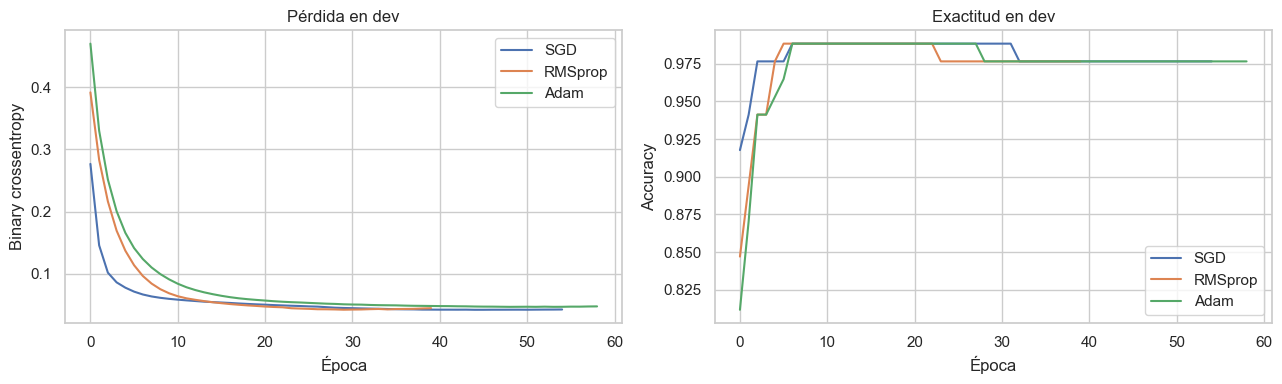

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for nombre, historia in historias.items():
    axes[0].plot(historia["val_loss"], label=nombre)
    axes[1].plot(historia["val_accuracy"], label=nombre)
axes[0].set(title="Pérdida en dev", xlabel="Época", ylabel="Binary crossentropy")
axes[1].set(title="Exactitud en dev", xlabel="Época", ylabel="Accuracy")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()


## 7 Regularización del modelo seleccionado

El optimizador se selecciona con dev. Luego se entrena otra red con regularización L2 en los pesos, Dropout del 30 % y Early Stopping. L2 desalienta pesos extremos; Dropout evita la dependencia excesiva entre neuronas; Early Stopping limita el entrenamiento cuando dev deja de mejorar.


In [8]:
mejor_optimizador = comparacion_optimizadores.loc[0, "Optimizador"]
modelo_base = modelos[mejor_optimizador]

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
modelo_regularizado = crear_modelo(
    fabricas_optimizadores[mejor_optimizador](),
    l2_strength=1e-4,
    dropout_rate=0.30,
)
parada_regularizada = EarlyStopping(
    monitor="val_loss", patience=12, restore_best_weights=True
)
historia_regularizada = modelo_regularizado.fit(
    X_train_s, y_train,
    validation_data=(X_dev_s, y_dev),
    epochs=120,
    batch_size=32,
    callbacks=[parada_regularizada],
    verbose=0,
)

print("Optimizador seleccionado con dev:", mejor_optimizador)
print("Épocas del modelo regularizado:", len(historia_regularizada.history["loss"]))


W0000 00:00:1791684296.370900 62118941 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1791684297.018231 62118941 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1791684297.649473 62118941 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


Optimizador seleccionado con dev: SGD
Épocas del modelo regularizado: 34


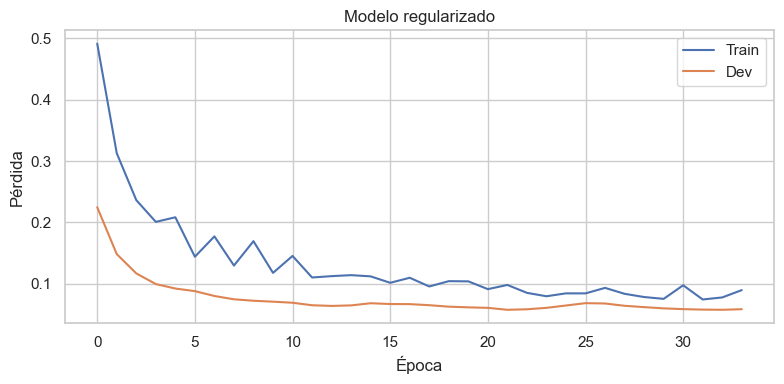

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(historia_regularizada.history["loss"], label="Train")
plt.plot(historia_regularizada.history["val_loss"], label="Dev")
plt.title("Modelo regularizado")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.tight_layout()
plt.show()


## 8 Evaluación final sobre test

Test se consulta al final. Además de Accuracy, se calculan Precision, Recall y F1 porque un único porcentaje de aciertos no muestra qué tipo de error comete el clasificador.


In [10]:
def metricas_binarias(modelo, nombre):
    probabilidades = modelo.predict(X_test_s, verbose=0).ravel()
    predicciones = (probabilidades >= 0.5).astype(int)
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, predicciones),
        "Precision": precision_score(y_test, predicciones),
        "Recall": recall_score(y_test, predicciones),
        "F1": f1_score(y_test, predicciones),
    }, predicciones


fila_base, pred_base = metricas_binarias(modelo_base, f"Base {mejor_optimizador}")
fila_reg, pred_reg = metricas_binarias(modelo_regularizado, "L2 + Dropout + Early Stopping")
metricas_test = pd.DataFrame([fila_base, fila_reg])
display(metricas_test.style.format({c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "F1"]}))


,Modelo,Accuracy,Precision,Recall,F1
0,Base SGD,0.9651,0.9811,0.9630,0.9720
1,L2 + Dropout + Early Stopping,0.9651,0.9811,0.9630,0.9720


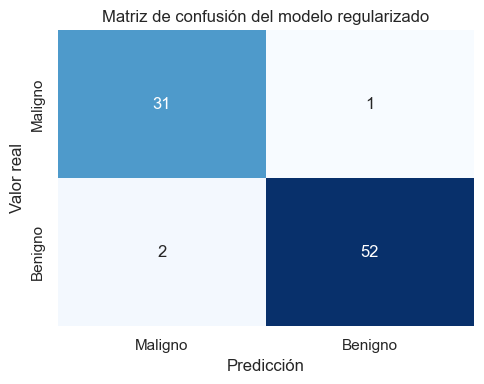

In [11]:
cm = confusion_matrix(y_test, pred_reg)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Maligno", "Benigno"], yticklabels=["Maligno", "Benigno"])
plt.title("Matriz de confusión del modelo regularizado")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.tight_layout()
plt.show()


## 9 Interpretación técnica

La diferencia entre train y dev representa una señal del tradeoff bias–variance. Un error alto en ambos conjuntos sugiere bias o subajuste; un desempeño alto en train y menor en dev sugiere variance o sobreajuste. La regularización puede reducir esa separación, aunque también puede introducir un poco más de bias. Por eso la configuración se elige con dev y se reporta el resultado independiente de test.


In [12]:
resultado_exportable = {
    "mejor_optimizador": mejor_optimizador,
    "epochs_regularizado": len(historia_regularizada.history["loss"]),
    "metricas_test_regularizado": {
        clave: round(float(fila_reg[clave]), 6)
        for clave in ["Accuracy", "Precision", "Recall", "F1"]
    },
    "matriz_confusion": cm.tolist(),
}
print("RESULTADOS_JSON:" + json.dumps(resultado_exportable, ensure_ascii=False))


RESULTADOS_JSON:{"mejor_optimizador": "SGD", "epochs_regularizado": 34, "metricas_test_regularizado": {"Accuracy": 0.965116, "Precision": 0.981132, "Recall": 0.962963, "F1": 0.971963}, "matriz_confusion": [[31, 1], [2, 52]]}


## 10 Conclusiones

La práctica separa la búsqueda de hiperparámetros de la evaluación final. Los optimizadores se comparan con dev y test queda reservado para el modelo elegido. La combinación de L2, Dropout y Early Stopping controla la complejidad desde mecanismos complementarios. Las métricas y la matriz de confusión permiten interpretar los aciertos y errores por clase, en lugar de depender solo de Accuracy.
